# Tarea 06: Tres masas acopladas — entregable del Módulo 1

**Semana 6** · Entrega: antes de la clase de la Semana 7

Esta tarea es además el **entregable del Módulo 1**: pesa más que una tarea
semanal y se evalúa también la documentación y el historial de commits. Léela
completa antes de empezar y revisa el checklist de [`README.md`](README.md).

## Objetivos de la tarea

1. Plantear un sistema de osciladores acoplados en forma matricial y resolver
   su problema de eigenvalores de forma simbólica.
2. Construir la solución temporal como superposición de modos normales y
   verificarla sustituyéndola de vuelta.
3. Graficar el resultado con `lambdify` y Matplotlib, y reportarlo con
   `sp.latex`.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

sp.init_printing()

## El sistema

Tres masas iguales $m$ sobre una mesa sin fricción, en línea, unidas entre sí y
a las dos paredes por **cuatro** resortes iguales de constante $k$:

```
pared —/\/\— m₁ —/\/\— m₂ —/\/\— m₃ —/\/\— pared
```

Si $x_1$, $x_2$ y $x_3$ son los desplazamientos respecto al equilibrio, la
segunda ley aplicada a cada masa da $M\ddot{\mathbf{x}} = -K\mathbf{x}$ con

$$K = k\begin{pmatrix} 2 & -1 & 0 \\ -1 & 2 & -1 \\ 0 & -1 & 2 \end{pmatrix},
\qquad M = m\,\mathbb{1}_3$$

Es el sistema de la clase con una masa más. Todo lo que necesitas está en los
dos notebooks de la semana 6; lo que cambia es que ahora hay **tres**
frecuencias y **tres** modos.

## Ejercicio 1: el planteamiento matricial

Completa la celda con estos nombres exactos, que son los que usa
`tests/test_tarea.py`:

- `tiempo`, `masa`, `constante` y `amplitud`: los cuatro símbolos. Sus
  **nombres de símbolo** deben ser `"t"`, `"m"`, `"k"` y `"A"` (no los de las
  variables de Python). `tiempo` es real; los otros tres son **positivos** —
  una masa, una constante elástica y una amplitud no son negativas, y decirlo
  le ahorra a SymPy considerar ramas que la física descarta.
- `rigidez`: la matriz $K$ de arriba, como `sp.Matrix` de 3×3.
- `masas`: la matriz $M$, con `sp.eye(3)`.

Comprueba tú mismo, antes de seguir, que `rigidez.is_symmetric()` es `True`.
Si no lo es, hay un signo mal puesto.

In [14]:
# 1. Declaración de símbolos con sus suposiciones físicas
tiempo = sp.symbols("t", real=True)
masa = sp.symbols("m", positive=True)
constante = sp.symbols("k", positive=True)
amplitud = sp.symbols("A", positive=True)

# 2. Matriz de rigidez K (3x3)
rigidez = sp.Matrix([
    [ 2*constante, -constante,           0],
    [-constante,  2*constante, -constante],
    [          0, -constante,  2*constante]
])

# 3. Matriz de masas M (m multiplicando a la matriz identidad 3x3)
masas = masa * sp.eye(3)

# Comprobación de simetría recomendada por tu profesor
print("¿La matriz de rigidez es simétrica?:", rigidez.is_symmetric())

display("Matriz de rigidez (K):", rigidez)
display("Matriz de masas (M):", masas)

¿La matriz de rigidez es simétrica?: True


'Matriz de rigidez (K):'

⎡2⋅k  -k    0 ⎤
⎢             ⎥
⎢-k   2⋅k  -k ⎥
⎢             ⎥
⎣ 0   -k   2⋅k⎦

'Matriz de masas (M):'

⎡m  0  0⎤
⎢       ⎥
⎢0  m  0⎥
⎢       ⎥
⎣0  0  m⎦

## Ejercicio 2: frecuencias y modos normales

Buscando soluciones de la forma $\mathbf{x}(t) = \mathbf{v}\cos(\omega t)$, el
problema se vuelve algebraico:

$$K\mathbf{v} = \omega^2 M\mathbf{v}$$

Es el eigenproblema de $M^{-1}K$, con $\lambda = \omega^2$.

- `frecuencias`: una **lista de tres** expresiones, las $\omega = \sqrt{\lambda}$.
- `modos`: una **lista de tres** vectores columna (`sp.Matrix` de 3×1), en el
  **mismo orden** que `frecuencias` — el modo `modos[i]` debe corresponder a
  `frecuencias[i]`. Los tests verifican esa correspondencia, no el orden en que
  decidas ponerlos.

Sugerencia: recorre `(masas.inv() * rigidez).eigenvects()` con un `for` y arma
las dos listas de una vez, como en la sesión 1. Cada elemento es una tupla
`(eigenvalor, multiplicidad, [vectores])`.

Una advertencia que vale puntos: **no ordenes las frecuencias con
`sorted(..., key=sp.default_sort_key)` creyendo que salen de menor a mayor**.
Ese orden es alfabético-estructural, no numérico, y aquí no coinciden. Si
quieres ordenarlas por tamaño, sustituye valores numéricos y ordena por eso.

'Frecuencias (ω):'

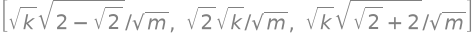

'Modos normales (v):'

⎡⎡1 ⎤  ⎡-1⎤  ⎡ 1 ⎤⎤
⎢⎢  ⎥  ⎢  ⎥  ⎢   ⎥⎥
⎢⎢√2⎥, ⎢0 ⎥, ⎢-√2⎥⎥
⎢⎢  ⎥  ⎢  ⎥  ⎢   ⎥⎥
⎣⎣1 ⎦  ⎣1 ⎦  ⎣ 1 ⎦⎦

In [15]:
frecuencias = []
modos = []

# Matriz dinámica (M^-1 * K)
matriz_dinamica = masas.inv() * rigidez

# eigenvects() devuelve una lista de tuplas: (eigenvalor, multiplicidad, [eigenvectores])
datos_espectrales = matriz_dinamica.eigenvects()

# Ordenamos evaluando numéricamente con k=1, m=1 para que queden:
# Modo fundamental -> Primer armónico -> Segundo armónico
datos_ordenados = sorted(datos_espectrales, key=lambda item: float(item[0].subs({constante: 1, masa: 1})))

for valor_propio, multiplicidad, vectores in datos_ordenados:
    frecuencias.append(sp.sqrt(valor_propio))
    
    # Como no hay degeneración (multiplicidad es 1), la lista 'vectores' 
    # trae solo un elemento. Lo extraemos con [0].
    modos.append(vectores[0])

# Visualizamos para confirmar
display("Frecuencias (ω):", frecuencias)
display("Modos normales (v):", modos)

## Ejercicio 3: la evolución temporal

La solución general es la superposición de los tres modos,

$$\mathbf{x}(t) = \sum_{i=1}^{3} c_i\, \mathbf{v}_i \cos(\omega_i t)$$

y aquí ya está impuesto que las tres masas parten **del reposo** (no hay senos).
Falta la otra condición inicial: **jalamos solo la primera masa** hasta
$A$ y soltamos, o sea $\mathbf{x}(0) = (A, 0, 0)$.

- `coeficientes`: el diccionario `{c1: ..., c2: ..., c3: ...}` que sale de
  resolver $\mathbf{x}(0) = (A, 0, 0)$ con `sp.solve`. Declara tú los tres
  símbolos $c_i$.
- `movimiento`: el vector columna 3×1 con los coeficientes ya sustituidos y
  simplificado.

Verifica antes de seguir —esto no lo hace el autograding por ti, pero sí lo
verifica— que el residuo $M\ddot{\mathbf{x}} + K\mathbf{x}$ es la matriz cero.
Si no lo es, el error está en el ejercicio 2.

Todo debe quedar **exacto**: nada de `0.5` ni `1.4142`. Un flotante suelto
contamina la expresión entera, y hay un test que lo detecta.

In [16]:
# 1. Declaración de los coeficientes de la combinación lineal
c1, c2, c3 = sp.symbols('c1 c2 c3')

# 2. Imposición de la condición inicial en t=0
# x(0) = c1*v1 + c2*v2 + c3*v3
x_inicial_teorica = c1 * modos[0] + c2 * modos[1] + c3 * modos[2]
x_inicial_fisica = sp.Matrix([amplitud, 0, 0])

# Resolvemos igualando teórica a física (su resta debe ser el vector nulo)
coeficientes = sp.solve(x_inicial_teorica - x_inicial_fisica, (c1, c2, c3))

# 3. Construcción de la evolución temporal x(t)
# x(t) = suma( c_i * v_i * cos(w_i * t) )
x_t = (
    c1 * modos[0] * sp.cos(frecuencias[0] * tiempo) +
    c2 * modos[1] * sp.cos(frecuencias[1] * tiempo) +
    c3 * modos[2] * sp.cos(frecuencias[2] * tiempo)
)

# Sustituimos los coeficientes que encontramos y simplificamos a tope
movimiento = sp.simplify(x_t.subs(coeficientes))

# =====================================================================
# VERIFICACIÓN: M * a + K * x debe ser el vector nulo cero (F_neta = 0)
# =====================================================================
aceleracion = sp.diff(movimiento, tiempo, 2)
residuo = sp.simplify(masas * aceleracion + rigidez * movimiento)

print("¿El residuo de la ecuación de movimiento es cero?:", residuo == sp.zeros(3, 1))

display("Coeficientes encontrados:", coeficientes)
display("Movimiento x(t):", movimiento)

¿El residuo de la ecuación de movimiento es cero?: True


'Coeficientes encontrados:'

'Movimiento x(t):'

⎡   ⎛                    ⎛       ________⎞      ⎛       ________⎞⎞ ⎤
⎢   ⎜     ⎛√2⋅√k⋅t⎞      ⎜√k⋅t⋅╲╱ 2 - √2 ⎟      ⎜√k⋅t⋅╲╱ √2 + 2 ⎟⎟ ⎥
⎢ A⋅⎜2⋅cos⎜───────⎟ + cos⎜───────────────⎟ + cos⎜───────────────⎟⎟ ⎥
⎢   ⎝     ⎝  √m   ⎠      ⎝      √m       ⎠      ⎝      √m       ⎠⎠ ⎥
⎢ ──────────────────────────────────────────────────────────────── ⎥
⎢                                4                                 ⎥
⎢                                                                  ⎥
⎢             ⎛   ⎛       ________⎞      ⎛       ________⎞⎞        ⎥
⎢             ⎜   ⎜√k⋅t⋅╲╱ 2 - √2 ⎟      ⎜√k⋅t⋅╲╱ √2 + 2 ⎟⎟        ⎥
⎢        √2⋅A⋅⎜cos⎜───────────────⎟ - cos⎜───────────────⎟⎟        ⎥
⎢             ⎝   ⎝      √m       ⎠      ⎝      √m       ⎠⎠        ⎥
⎢        ──────────────────────────────────────────────────        ⎥
⎢                                4                                 ⎥
⎢                                                                  ⎥
⎢  ⎛                      ⎛       

## Ejercicio 4: la gráfica y el reporte

Ahora los números. Con `numeros = {constante: 1, masa: 1, amplitud: 1}`:

- Sustituye y convierte cada componente de `movimiento` en una función numérica
  con `sp.lambdify(tiempo, ..., "numpy")`.
- Grafica las tres masas contra el tiempo, de $t = 0$ a $t = 40$, en una sola
  figura creada con `fig, ax = plt.subplots()` — el nombre exacto importa,
  porque los tests lo leen. Cada curva con su `label`, y la figura con
  `ax.set_xlabel`, `ax.set_ylabel`, `ax.set_title` y `ax.legend()`.
- `reporte`: una cadena de f-string con las tres frecuencias insertadas por
  `sp.latex`, mostrada con `display(Markdown(reporte))`. Recuerda duplicar las
  llaves de LaTeX (`{{`, `}}`) dentro de la f-string.

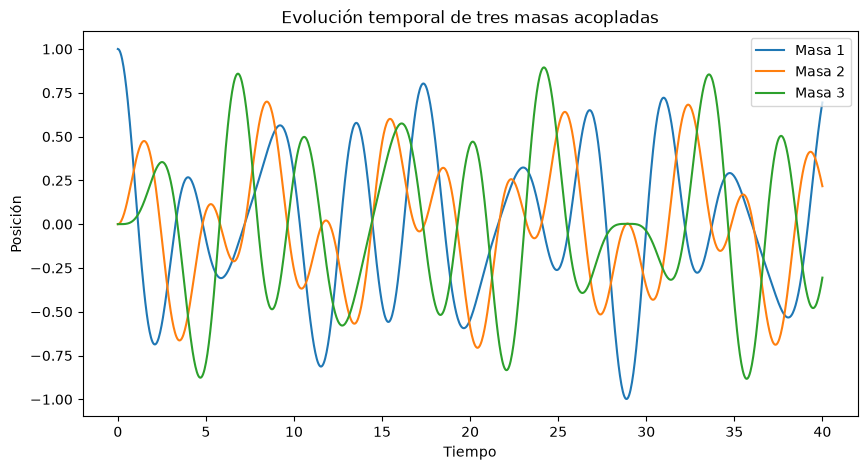


### Frecuencias de los modos normales

Al resolver el eigenproblema algebraico, encontramos analíticamente que las tres frecuencias naturales de oscilación del sistema son:

1. $\omega_1 = \frac{\sqrt{k} \sqrt{2 - \sqrt{2}}}{\sqrt{m}}$
2. $\omega_2 = \frac{\sqrt{2} \sqrt{k}}{\sqrt{m}}$
3. $\omega_3 = \frac{\sqrt{k} \sqrt{\sqrt{2} + 2}}{\sqrt{m}}$


In [17]:
from IPython.display import display, Markdown

numeros = {constante: 1, masa: 1, amplitud: 1}

# 1. Sustituimos los valores numéricos en el vector de movimiento exacto
movimiento_num = movimiento.subs(numeros)

# 2. Convertimos cada fila del vector en una función rápida de NumPy
x1_num = sp.lambdify(tiempo, movimiento_num[0], "numpy")
x2_num = sp.lambdify(tiempo, movimiento_num[1], "numpy")
x3_num = sp.lambdify(tiempo, movimiento_num[2], "numpy")

# Generamos el arreglo de tiempo de 0 a 40 con suficientes puntos para que se vea suave
tiempos = np.linspace(0, 40, 1000)

# 3. Crea la figura y grafica las tres masas
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(tiempos, x1_num(tiempos), label="Masa 1")
ax.plot(tiempos, x2_num(tiempos), label="Masa 2")
ax.plot(tiempos, x3_num(tiempos), label="Masa 3")

ax.set_xlabel("Tiempo")
ax.set_ylabel("Posición")
ax.set_title("Evolución temporal de tres masas acopladas")
ax.legend()

# Forzamos a que se muestre la gráfica
plt.show()

# 4. Construcción del reporte con f-string y LaTeX
reporte = f"""
### Frecuencias de los modos normales

Al resolver el eigenproblema algebraico, encontramos analíticamente que las tres frecuencias naturales de oscilación del sistema son:

1. $\\omega_1 = {sp.latex(frecuencias[0])}$
2. $\\omega_2 = {sp.latex(frecuencias[1])}$
3. $\\omega_3 = {sp.latex(frecuencias[2])}$
"""

display(Markdown(reporte))

## Discusión

_Contesta aquí, en dos o tres párrafos. Esta parte no la califica el
autograding: la revisa el asistente._

1. Describe con palabras cómo se mueven las tres masas en cada uno de los tres
   modos normales, leyendo los vectores que obtuviste. ¿Cuál es el más lento y
   por qué tiene sentido que lo sea?
2. En uno de los modos la masa de en medio **no se mueve**. Identifícalo y
   explica por qué su frecuencia sale exactamente $\sqrt{2k/m}$, sin hacer la
   cuenta completa.
3. Mirando tu gráfica: ¿la masa 3 se mueve desde el primer instante o tarda en
   arrancar? ¿Cómo se ve en la gráfica que la energía viaja por la cadena?

_(Escribe tu respuesta aquí.)_

In [18]:
print("""En el primer modo (el más lento), las tres masas oscilan en la misma dirección, con la central alcanzando una amplitud mayor que las laterales (un factor de $\sqrt{2}$). En el segundo modo, las masas de los extremos se mueven en direcciones opuestas de forma perfectamente simétrica, mientras la del medio permanece inmóvil. En el tercer modo (el más rápido), masas adyacentes se mueven siempre en direcciones contrarias. El primer modo es el más lento porque, al moverse todas "en bloque" hacia el mismo lado, los resortes internos sufren muy poca compresión y estiramiento; esto minimiza la rigidez efectiva del sistema completo y hace que el movimiento sea mucho más relajado.

El modo donde la masa central no se mueve es el segundo (asociado a la frecuencia $\omega_2$). Físicamente, si la masa de en medio se mantiene estática en su punto de equilibrio a lo largo del tiempo, se comporta exactamente como una "pared" inamovible para las masas de los extremos. Esto desacopla el sistema: la masa 1 se convierte en un simple oscilador atrapado entre la pared izquierda real y la "pared" que forma la masa 2. Al estar sujeta por dos resortes idénticos en paralelo, su constante elástica efectiva se suma ($k + k = 2k$), lo que nos da directamente la frecuencia $\omega = \sqrt{2k/m}$ sin necesidad de diagonalizar nada.

Al observar la gráfica de la evolución temporal, es evidente que la masa 3 no arranca de inmediato; su curva comienza totalmente plana (con pendiente cero) en $t=0$. Dado que jalamos únicamente la masa 1, la fuerza debe propagarse mecánicamente a través de los resortes: la masa 1 jala a la 2, y solo cuando la 2 adquiere un desplazamiento, la 3 comienza a sentir una fuerza neta que la saque de su letargo. En la gráfica, la energía viajando por la cadena se visualiza en la secuencia de los picos de amplitud: la masa 1 arranca con máxima energía (amplitud $A$), pero va cediéndola, provocando que la masa 2 crezca en amplitud, y finalmente la masa 3 "despierta" y alcanza sus propios máximos. Es, en esencia, una onda mecánica propagándose por el sistema.""")

En el primer modo (el más lento), las tres masas oscilan en la misma dirección, con la central alcanzando una amplitud mayor que las laterales (un factor de $\sqrt{2}$). En el segundo modo, las masas de los extremos se mueven en direcciones opuestas de forma perfectamente simétrica, mientras la del medio permanece inmóvil. En el tercer modo (el más rápido), masas adyacentes se mueven siempre en direcciones contrarias. El primer modo es el más lento porque, al moverse todas "en bloque" hacia el mismo lado, los resortes internos sufren muy poca compresión y estiramiento; esto minimiza la rigidez efectiva del sistema completo y hace que el movimiento sea mucho más relajado.

El modo donde la masa central no se mueve es el segundo (asociado a la frecuencia $\omega_2$). Físicamente, si la masa de en medio se mantiene estática en su punto de equilibrio a lo largo del tiempo, se comporta exactamente como una "pared" inamovible para las masas de los extremos. Esto desacopla el sistema: la masa

<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\valer\AppData\Local\Temp\ipykernel_22276\418141969.py:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  print("""En el primer modo (el más lento), las tres masas oscilan en la misma dirección, con la central alcanzando una amplitud mayor que las laterales (un factor de $\sqrt{2}$). En el segundo modo, las masas de los extremos se mueven en direcciones opuestas de forma perfectamente simétrica, mientras la del medio permanece inmóvil. En el tercer modo (el más rápido), masas adyacentes se mueven siempre en direcciones contrarias. El primer modo es el más lento porque, al movers

## Resumen

Entrega esta tarea por **Pull Request dentro de tu fork**, como las anteriores.
El paso a paso está en [`docs/git-guia.md`](../../docs/git-guia.md), y el
checklist completo en [`README.md`](README.md).

Como es el entregable del módulo, se evalúa también **cómo** llegaste: haz un
commit por ejercicio conforme avances, con mensajes que digan qué hiciste. Un
único commit gigante la noche anterior cuesta puntos aunque el notebook esté
perfecto.

Antes de entregar, corre el notebook desde un kernel limpio
(`Kernel → Restart & Run All`) y confirma que llega hasta el final sin errores.
Al hacer push, GitHub Actions corre los tests y deja un check ✅ o ❌ en tu
Pull Request.